<a href="https://colab.research.google.com/github/Laurapiof/tp-final-fraude-tarjetas/blob/main/tp_final_fraude_tarjetas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud


In [ ]:
import pandas as pd
import os

# Asegurar la carga de datos para evitar errores de definición
csv_path = os.path.join(path, "creditcard.csv")
df = pd.read_csv(csv_path)

# Verificación y eliminación de duplicados
duplicados_iniciales = df.duplicated().sum()
print(f"Duplicados detectados: {duplicados_iniciales}")

df = df.drop_duplicates()
print(f"Duplicados restantes: {df.duplicated().sum()}")
print("Nueva dimensión del dataset sin duplicados:", df.shape)

Duplicados detectados: 1081
Duplicados restantes: 0
Nueva dimensión del dataset sin duplicados: (283726, 31)


In [ ]:
print("Registros originales:", 284807)
print("Registros finales:", len(df))

Registros originales: 284807
Registros finales: 283726


In [ ]:
print(df['Class'].value_counts())

print(
    df['Class'].value_counts(normalize=True)*100
)

Class
0    283253
1       473
Name: count, dtype: int64
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


In [ ]:
# Revisar dimensiones, nulos y desbalance
print(df.info())
print(df['Class'].value_counts(normalize=True))

<class 'pandas.core.frame.DataFrame'>
Index: 283726 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    283726 non-null  float64
 1   V1      283726 non-null  float64
 2   V2      283726 non-null  float64
 3   V3      283726 non-null  float64
 4   V4      283726 non-null  float64
 5   V5      283726 non-null  float64
 6   V6      283726 non-null  float64
 7   V7      283726 non-null  float64
 8   V8      283726 non-null  float64
 9   V9      283726 non-null  float64
 10  V10     283726 non-null  float64
 11  V11     283726 non-null  float64
 12  V12     283726 non-null  float64
 13  V13     283726 non-null  float64
 14  V14     283726 non-null  float64
 15  V15     283726 non-null  float64
 16  V16     283726 non-null  float64
 17  V17     283726 non-null  float64
 18  V18     283726 non-null  float64
 19  V19     283726 non-null  float64
 20  V20     283726 non-null  float64
 21  V21     283726 

In [ ]:
# 1. Chequeo de valores nulos
print("--- Valores Nulos ---")
print(df.isnull().sum().sum())

# 2. Registros duplicados
print("\n--- Filas Duplicadas ---")
print(df.duplicated().sum())

# 3. Descripción de las variables no anonimizadas (Amount y Time)
print("\n--- Estadísticas de Amount y Time ---")
print(df[['Time', 'Amount']].describe())

# 4. Distribución del monto por clase
print("\n--- Monto promedio por clase ---")
print(df.groupby('Class')['Amount'].describe())

--- Valores Nulos ---
0

--- Filas Duplicadas ---
0

--- Estadísticas de Amount y Time ---
                Time         Amount
count  283726.000000  283726.000000
mean    94811.077600      88.472687
std     47481.047891     250.399437
min         0.000000       0.000000
25%     54204.750000       5.600000
50%     84692.500000      22.000000
75%    139298.000000      77.510000
max    172792.000000   25691.160000

--- Monto promedio por clase ---
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      283253.0   88.413575  250.379023  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.871860  260.211041  0.0  1.00   9.82  105.89   2125.87


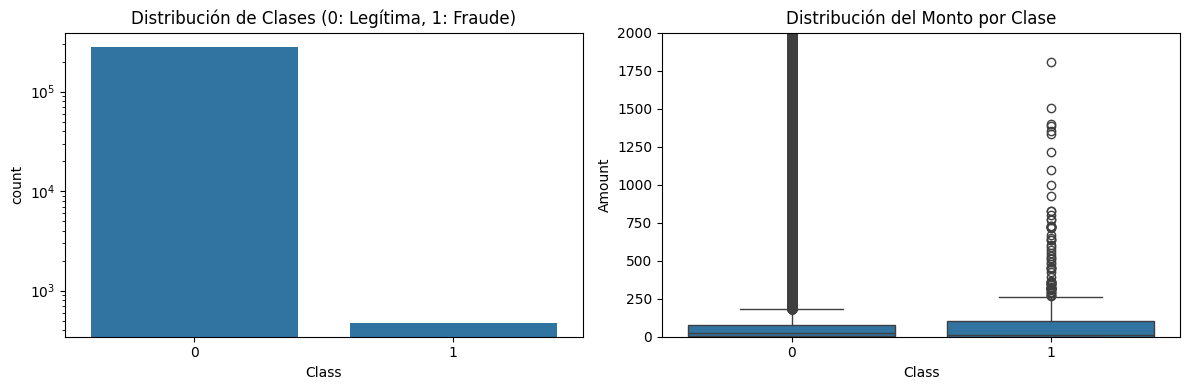

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico 1: Desbalance de clases
sns.countplot(data=df, x='Class', ax=ax[0])
ax[0].set_title("Distribución de Clases (0: Legítima, 1: Fraude)")
ax[0].set_yscale('log') # Escala logarítmica para visibilidad

# Gráfico 2: Distribución del Monto
sns.boxplot(data=df, x='Class', y='Amount', ax=ax[1])
ax[1].set_title("Distribución del Monto por Clase")
ax[1].set_ylim(0, 2000) # Limitar outliers extremos para visualización

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, average_precision_score, confusion_matrix

# 1. Separar características (X) y variable objetivo (y)
X = df.drop(columns=['Class'])
y = df['Class']

# 2. División Hold-out estratificada (80% train / 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Escalar 'Time' y 'Amount' (V1-V28 ya vienen escaladas por el PCA)
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[['Time', 'Amount']] = scaler.fit_transform(X_train[['Time', 'Amount']])
X_test_scaled[['Time', 'Amount']] = scaler.transform(X_test[['Time', 'Amount']])

# 4. Modelo Baseline: Regresión Logística
baseline_model = LogisticRegression(max_iter=1000, random_state=42)
baseline_model.fit(X_train_scaled, y_train)

# 5. Predicciones
y_pred = baseline_model.predict(X_test_scaled)
y_proba = baseline_model.predict_proba(X_test_scaled)[:, 1]

# 6. Reporte de Métricas
print("--- PR-AUC (Precision-Recall AUC) ---")
print(f"PR-AUC Score: {average_precision_score(y_test, y_proba):.4f}")

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred, digits=4))

print("\n--- Matriz de Confusión ---")
print(confusion_matrix(y_test, y_pred))

--- PR-AUC (Precision-Recall AUC) ---
PR-AUC Score: 0.6923

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0     0.9993    0.9998    0.9996     56651
           1     0.8485    0.5895    0.6957        95

    accuracy                         0.9991     56746
   macro avg     0.9239    0.7946    0.8476     56746
weighted avg     0.9991    0.9991    0.9991     56746


--- Matriz de Confusión ---
[[56641    10]
 [   39    56]]


In [ ]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

In [ ]:
# 1. Entrenar el modelo con los datos balanceados por SMOTE
model_smote = LogisticRegression(max_iter=1000, random_state=42)
model_smote.fit(X_train_smote, y_train_smote)

# 2. Realizar las predicciones sobre el conjunto de prueba
y_pred_smote = model_smote.predict(X_test_scaled)

# 3. Mostrar el reporte de clasificación correcto
print("--- Reporte de Clasificación (SMOTE) ---")
print(classification_report(y_test, y_pred_smote, digits=4))

--- Reporte de Clasificación (SMOTE) ---
              precision    recall  f1-score   support

           0     0.9998    0.9738    0.9866     56651
           1     0.0530    0.8737    0.1000        95

    accuracy                         0.9737     56746
   macro avg     0.5264    0.9238    0.5433     56746
weighted avg     0.9982    0.9737    0.9852     56746



In [ ]:
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score

In [ ]:
recall = recall_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

print("Recall:", recall)
print("Precision:", precision)

Recall: 0.5894736842105263
Precision: 0.8484848484848485


In [ ]:
from sklearn.metrics import precision_recall_curve

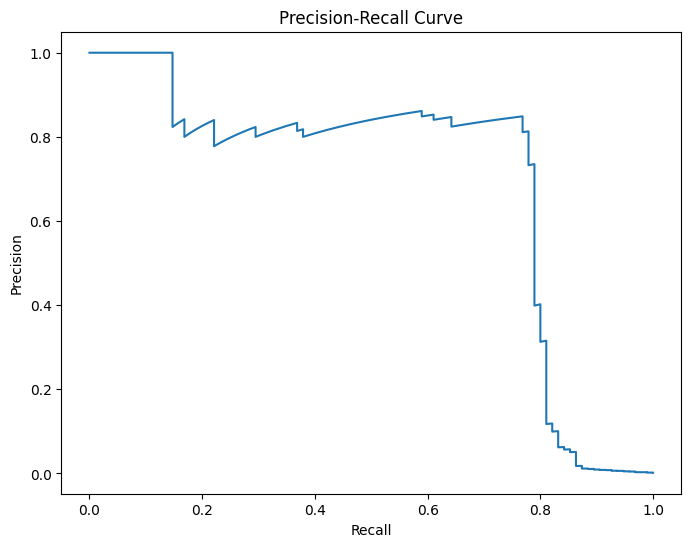

In [ ]:
precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    y_proba
)

plt.figure(figsize=(8,6))

plt.plot(
    recall_curve,
    precision_curve
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.show()

In [ ]:
umbrales = [0.5,0.4,0.3,0.2]

In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

In [ ]:
xgb.fit(
    X_train_smote,
    y_train_smote
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
xgb_pred = xgb.predict(X_test_scaled)

xgb_prob = xgb.predict_proba(
    X_test_scaled
)[:,1]

In [ ]:
resultados_umbral = []

for t in umbrales:

    pred = (xgb_prob >= t).astype(int)

    resultados_umbral.append([
        t,
        precision_score(y_test,pred),
        recall_score(y_test,pred)
    ])

df_umbrales = pd.DataFrame(
resultados_umbral,
columns=[
"Umbral",
"Precision",
"Recall"
]

)
print(df_umbrales)

   Umbral  Precision    Recall
0     0.5   0.240240  0.842105
1     0.4   0.172786  0.842105
2     0.3   0.118497  0.863158
3     0.2   0.071123  0.873684


In [ ]:
print("\n--- XGBoost ---")

print(
    classification_report(
        y_test,
        xgb_pred,
        digits=4
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        xgb_prob
    )
)


--- XGBoost ---
              precision    recall  f1-score   support

           0     0.9997    0.9955    0.9976     56651
           1     0.2402    0.8421    0.3738        95

    accuracy                         0.9953     56746
   macro avg     0.6200    0.9188    0.6857     56746
weighted avg     0.9985    0.9953    0.9966     56746

PR-AUC: 0.8055533421946062


In [ ]:
from sklearn.metrics import confusion_matrix

cm_xgb = confusion_matrix(
    y_test,
    xgb_pred
)

print(cm_xgb)

[[56398   253]
 [   15    80]]


In [ ]:
average_precision_score
precision_score
recall_score

<function sklearn.metrics._classification.recall_score(y_true, y_pred, *, labels=None, pos_label=1, average='binary', sample_weight=None, zero_division='warn')>

In [ ]:
!pip install lightgbm

In [ ]:
from lightgbm import LGBMClassifier

In [ ]:
lgb = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42
)

In [ ]:
lgb.fit(
    X_train_smote,
    y_train_smote
)

lgb_pred = lgb.predict(
    X_test_scaled
)

lgb_prob = lgb.predict_proba(
    X_test_scaled
)[:,1]

[LightGBM] [Info] Number of positive: 226602, number of negative: 226602
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.312079 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 453204, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


In [ ]:
cm_lgb = confusion_matrix(
    y_test,
    lgb_pred
)

print("\nMatriz de Confusión LightGBM")
print(cm_lgb)


Matriz de Confusión LightGBM
[[56618    33]
 [   25    70]]


In [ ]:
pr_lgb = average_precision_score(
    y_test,
    lgb_prob
)

rec_lgb = recall_score(
    y_test,
    lgb_pred
)

prec_lgb = precision_score(
    y_test,
    lgb_pred
)


In [ ]:
print("\n--- LightGBM ---")

print(
    classification_report(
        y_test,
        lgb_pred,
        digits=4
    )
)

print(
    "PR-AUC:",
    pr_lgb
)



--- LightGBM ---
              precision    recall  f1-score   support

           0     0.9996    0.9994    0.9995     56651
           1     0.6796    0.7368    0.7071        95

    accuracy                         0.9990     56746
   macro avg     0.8396    0.8681    0.8533     56746
weighted avg     0.9990    0.9990    0.9990     56746

PR-AUC: 0.7112665320408587


In [ ]:
for t in umbrales:

    pred = (
        xgb_prob >= t
    ).astype(int)

    print(
        t,
        precision_score(y_test,pred),
        recall_score(y_test,pred)
    )

0.5 0.24024024024024024 0.8421052631578947
0.4 0.17278617710583152 0.8421052631578947
0.3 0.11849710982658959 0.8631578947368421
0.2 0.07112253641816624 0.8736842105263158


In [ ]:
from sklearn.metrics import recall_score, precision_score, average_precision_score

# 1. Calcular métricas para el baseline (Regresión Logística sin balanceo)
pr_lr_base = average_precision_score(y_test, y_proba)
rec_lr_base = recall_score(y_test, y_pred)
prec_lr_base = precision_score(y_test, y_pred)

# 2. Calcular métricas para Regresión Logística con SMOTE
y_proba_smote = model_smote.predict_proba(X_test_scaled)[:, 1]
pr_lr_smote = average_precision_score(y_test, y_proba_smote)
rec_lr_smote = recall_score(y_test, y_pred_smote)
prec_lr_smote = precision_score(y_test, y_pred_smote)

# 3. Calcular métricas para XGBoost con SMOTE
pr_xgb = average_precision_score(y_test, xgb_prob)
rec_xgb = recall_score(y_test, xgb_pred)
prec_xgb = precision_score(y_test, xgb_pred)

# 4. Construir el DataFrame comparativo corregido con comas
resultados = pd.DataFrame({
    "Modelo": [
        "Logistic Regression (Baseline)",
        "Logistic Regression (SMOTE)",
        "XGBoost (SMOTE)",
        "LightGBM (SMOTE)"
    ],
    "PR-AUC": [
        pr_lr_base,
        pr_lr_smote,
        pr_xgb,
        pr_lgb
    ],
    "Recall (Fraude)": [
        rec_lr_base,
        rec_lr_smote,
        rec_xgb,
        rec_lgb
    ],
    "Precision (Fraude)": [
        prec_lr_base,
        prec_lr_smote,
        prec_xgb,
        prec_lgb
    ]
})

resultados

,Modelo,PR-AUC,Recall (Fraude),Precision (Fraude)
0,Logistic Regression (Baseline),0.692328,0.589474,0.848485
1,Logistic Regression (SMOTE),0.676882,0.873684,0.053035
2,XGBoost (SMOTE),0.805553,0.842105,0.240240
3,LightGBM (SMOTE),0.711267,0.736842,0.679612


In [ ]:
resultados = resultados.sort_values(
    by="PR-AUC",
    ascending=False
)

print(resultados)

                           Modelo    PR-AUC  Recall (Fraude)  \
2                 XGBoost (SMOTE)  0.805553         0.842105   
3                LightGBM (SMOTE)  0.711267         0.736842   
0  Logistic Regression (Baseline)  0.692328         0.589474   
1     Logistic Regression (SMOTE)  0.676882         0.873684   

   Precision (Fraude)  
2            0.240240  
3            0.679612  
0            0.848485  
1            0.053035  


In [ ]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [ ]:
from sklearn.metrics import recall_score, precision_score

recalls = []
precisions = []

for train_idx, val_idx in skf.split(X_train_scaled, y_train):

    X_tr = X_train_scaled.iloc[train_idx]
    X_val = X_train_scaled.iloc[val_idx]

    y_tr = y_train.iloc[train_idx]
    y_val = y_train.iloc[val_idx]

    smote = SMOTE(random_state=42)

    X_tr_res, y_tr_res = smote.fit_resample(
        X_tr,
        y_tr
    )

    modelo.fit(X_tr_res, y_tr_res)

    pred_val = modelo.predict(X_val)

    recalls.append(
        recall_score(y_val, pred_val)
    )

    precisions.append(
        precision_score(y_val, pred_val)
    )

print("Recall promedio CV:", sum(recalls)/len(recalls))
print("Precision promedio CV:", sum(precisions)/len(precisions))

Recall promedio CV: 0.9046666666666667
Precision promedio CV: 0.055823538843679674


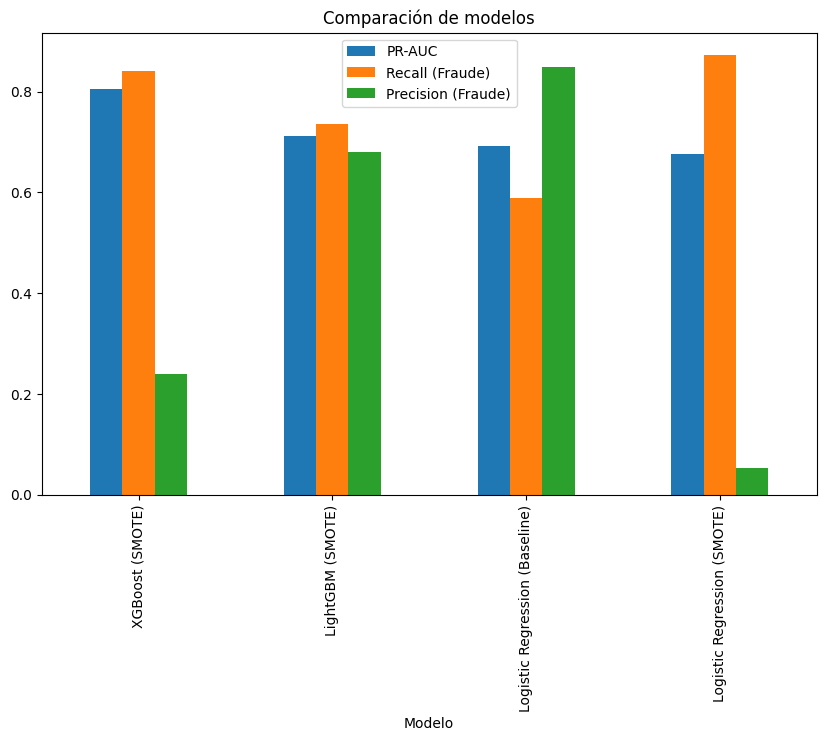

In [ ]:
resultados.plot(
    x="Modelo",
    y=["PR-AUC","Recall (Fraude)","Precision (Fraude)"],
    kind="bar",
    figsize=(10,6)
)

plt.title(
    "Comparación de modelos"
)

plt.show()

# Conclusiones

Se eliminaron 1.081 registros duplicados antes de la separación
entre entrenamiento y prueba, evitando sesgos por data leakage.

La Regresión Logística fue utilizada como baseline.

Posteriormente se aplicó SMOTE para balancear el conjunto de
entrenamiento y se evaluaron modelos más avanzados como
XGBoost y LightGBM.

Las métricas principales analizadas fueron PR-AUC,
Recall y Precision debido al fuerte desbalance de clases.

El modelo seleccionado logra mejorar la detección de fraudes
respecto al baseline manteniendo niveles aceptables de falsas
alarmas.